In [ ]:
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns
from typing import Literal, Optional, Tuple, Union, Dict, Any, List, Iterator
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error

"""	“Google, Virtual Assistant (VA) Gemini,” Various prompts “Guidance in code structure and syntax”. 
VAMMA (Virtual Assistant with Manual Modification and Arrangement, Gemini, Google). [Online]. Available: https://gemini.google.com/ """


# GLOBAL PLOTTING & ENVIRONMENT SETUP
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})

#pl.Config.set_tbl_rows(-1)             # shows all table rows globably
#pl.Config.set_tbl_cols(-1)             # shows all table columns globably
#pl.Config.set_fmt_str_lengths(100)     # increase character count visible globably
#pl.Config.restore_defaults()           # reset to default configuration

# Get current working directory (e.g., .\notebooks)
cwd = os.getcwd()

# Get parent folder to access (.\Data)
parent = os.path.dirname(cwd)

# Get file path to load into environment
file_path_EPTI_data = os.path.join(parent, "Data", "EPTI_Solar_data.parquet")

print(f"Loading dataset from: {file_path_EPTI_data}")
df = pl.read_parquet(file_path_EPTI_data).with_columns(pl.col(["Price_profile", "Price_level", "Region", "Which_Phases_Participate",
                                                                "Municipality", "Group_Phase2", "Control_Price_Phase2"]).cast(pl.Categorical))

Loading dataset from: c:\Users\Marty\Documents\School\Merrimack College\8) DSE6311 Data Science Capstone\team_omega\Data\EPTI_Solar_data.parquet


In [2]:
# Check for missing values
def what_percentage_missing(df):
    missing_percentage = (
        df.select((pl.all().is_null().sum() / pl.len()) * 100)
        .transpose(include_header=True, header_name="column", column_names=["pct_missing"])
        .sort("pct_missing", descending=True)
    )

    print("Percentage of missing values in each column:")

    with pl.Config(tbl_rows=-1):
        print(missing_percentage)

what_percentage_missing(df)

Percentage of missing values in each column:
shape: (24, 2)
┌──────────────────────────┬─────────────┐
│ column                   ┆ pct_missing │
│ ---                      ┆ ---         │
│ str                      ┆ f64         │
╞══════════════════════════╪═════════════╡
│ Price_profile            ┆ 88.006897   │
│ Price_level              ┆ 88.006897   │
│ Experiment_price_NOK_kWh ┆ 88.006897   │
│ ghi_Wh_m2                ┆ 0.03592     │
│ photons_m2               ┆ 0.03592     │
│ par_photons_m2           ┆ 0.03592     │
│ par_mol_m2               ┆ 0.03592     │
│ sun_minutes              ┆ 0.03592     │
│ ID                       ┆ 0.0         │
│ From                     ┆ 0.0         │
│ Date                     ┆ 0.0         │
│ Day_Of_Week              ┆ 0.0         │
│ Is_Weekend               ┆ 0.0         │
│ Hour                     ┆ 0.0         │
│ Demand_kWh               ┆ 0.0         │
│ Temperature              ┆ 0.0         │
│ Temperature24            ┆ 0.0     

In [3]:
# Create a boolean expression checking for "Control"
is_control = pl.col("Group_Phase2").cast(pl.String).str.contains("Control")

# Summary DataFrame with counts and percentages
summary_df = (
    df.with_columns(
        pl.when(is_control)
        .then(pl.lit("Control"))
        .otherwise(pl.lit("Experiment"))
        .alias("Cohort")
    )
    .group_by("Cohort")
    .agg(pl.len().alias("count"))
    .with_columns(
        (pl.col("count") / pl.col("count").sum() * 100).round(2).alias("pct")
    )
)

print(summary_df)

shape: (2, 3)
┌────────────┬─────────┬───────┐
│ Cohort     ┆ count   ┆ pct   │
│ ---        ┆ ---     ┆ ---   │
│ str        ┆ u32     ┆ f64   │
╞════════════╪═════════╪═══════╡
│ Experiment ┆ 8638752 ┆ 70.93 │
│ Control    ┆ 3541248 ┆ 29.07 │
└────────────┴─────────┴───────┘


In [4]:
# Subset containing Ber_Control, Bo_Control, Control, Os_Control, Trom_Control, Trond_Control
df_control = df.filter(is_control)

# Subset containing everything else (Ber_1, Bo_1, H1, H2, NA, Os_1..6, Trom_1..2, Trond_1)
df_experiment = df.filter(~is_control)

In [5]:
# just the dataframe with 
what_percentage_missing(df_experiment)

Percentage of missing values in each column:
shape: (24, 2)
┌──────────────────────────┬─────────────┐
│ column                   ┆ pct_missing │
│ ---                      ┆ ---         │
│ str                      ┆ f64         │
╞══════════════════════════╪═════════════╡
│ Price_profile            ┆ 83.090613   │
│ Price_level              ┆ 83.090613   │
│ Experiment_price_NOK_kWh ┆ 83.090613   │
│ ghi_Wh_m2                ┆ 0.03592     │
│ photons_m2               ┆ 0.03592     │
│ par_photons_m2           ┆ 0.03592     │
│ par_mol_m2               ┆ 0.03592     │
│ sun_minutes              ┆ 0.03592     │
│ ID                       ┆ 0.0         │
│ From                     ┆ 0.0         │
│ Date                     ┆ 0.0         │
│ Day_Of_Week              ┆ 0.0         │
│ Is_Weekend               ┆ 0.0         │
│ Hour                     ┆ 0.0         │
│ Demand_kWh               ┆ 0.0         │
│ Temperature              ┆ 0.0         │
│ Temperature24            ┆ 0.0     

In [6]:
# 100% missing - as expected
#what_percentage_missing(df_control)

In [7]:
# How many and what proportion of all days fall specifically on weekends: 2,376,394 Control-hours plus another 9,813 Experiment-hours are from a Weekend date 

total_rows = df.height
total_cols = df.width

stats = (
    df
    .filter(
        (pl.col("Is_Weekend") == 1)
        # & (pl.col("Experiment_price_NOK_kWh").is_not_null())
        # & (pl.col("Price_profile").is_not_null())
        # & (pl.col("Price_level").is_not_null())
    )
    .select(
        Match_Count=pl.len(),
        Control_Null_Count=pl.col("Price_level").is_null().sum(),
    )
    .with_columns(
        Pct_of_Total_DF=(pl.col("Match_Count") / total_rows) * 100,
        Control_Null_Pct_of_Total_DF=(pl.col("Control_Null_Count") / total_rows) * 100,
        Control_Null_Pct_of_Matches=(pl.col("Control_Null_Count") / pl.col("Match_Count")) * 100,
    )
)

print(f"Total rows in df: {total_rows} and Total columns in df: {total_cols}")
print(stats)

Total rows in df: 12180000 and Total columns in df: 24
shape: (1, 5)
┌─────────────┬────────────────────┬─────────────────┬──────────────────────┬──────────────────────┐
│ Match_Count ┆ Control_Null_Count ┆ Pct_of_Total_DF ┆ Control_Null_Pct_of_ ┆ Control_Null_Pct_of_ │
│ ---         ┆ ---                ┆ ---             ┆ Total_DF             ┆ Matches              │
│ u32         ┆ u32                ┆ f64             ┆ ---                  ┆ ---                  │
│             ┆                    ┆                 ┆ f64                  ┆ f64                  │
╞═════════════╪════════════════════╪═════════════════╪══════════════════════╪══════════════════════╡
│ 3364375     ┆ 3354562            ┆ 27.622126       ┆ 27.54156             ┆ 99.708326            │
└─────────────┴────────────────────┴─────────────────┴──────────────────────┴──────────────────────┘


In [8]:
# Very few occurances of Expermiental days - it is possible that some of these are just "bleed" from a Friday night midnight into Saturday
# We can not create an Is_Weekend variant of our proposed model, with these data. Bummer.
weekend_anomalies = (
    df
    .filter((pl.col("Is_Weekend") == 1) & (pl.col("Price_level").is_not_null()))
    .group_by(["Municipality", "Price_profile", "Hour"])
    .len()
    .sort("len", descending=True)
)

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(weekend_anomalies)

# Optional: Remove the 3,364,375 occurances of Control Weekend + 9,813 experiment occurances bleed into the weekend - so that the Is_Weekend column can be dropped
# Also this will ensure that our Baseline kWh measurement only uses weekday values from control - as those are the only days the Experiment was conducted
df_no_weekends = df.remove(pl.col("Is_Weekend") == 1)
print(f"Total rows in df: {df_no_weekends.height} and Total columns in df: {df_no_weekends.width}")


shape: (33, 4)
┌──────────────┬───────────────┬──────┬──────┐
│ Municipality ┆ Price_profile ┆ Hour ┆ len  │
│ ---          ┆ ---           ┆ ---  ┆ ---  │
│ cat          ┆ cat           ┆ i32  ┆ u32  │
╞══════════════╪═══════════════╪══════╪══════╡
│ Oslo         ┆ P             ┆ 0    ┆ 1076 │
│ Tromsø       ┆ P             ┆ 0    ┆ 1060 │
│ Tromsø       ┆ B             ┆ 0    ┆ 1036 │
│ Bergen       ┆ B             ┆ 0    ┆ 807  │
│ Trondheim    ┆ B             ┆ 0    ┆ 804  │
│ Oslo         ┆ B             ┆ 0    ┆ 648  │
│ Oslo         ┆ A             ┆ 0    ┆ 454  │
│ Oslo         ┆ C             ┆ 0    ┆ 449  │
│ Bodø         ┆ B             ┆ 0    ┆ 442  │
│ Oslo         ┆ P0            ┆ 0    ┆ 436  │
│ Bærum        ┆ P             ┆ 0    ┆ 337  │
│ Bærum        ┆ B             ┆ 0    ┆ 192  │
│ Lillestrøm   ┆ P             ┆ 0    ┆ 161  │
│ Stavanger    ┆ P             ┆ 0    ┆ 156  │
│ Stavanger    ┆ B             ┆ 0    ┆ 156  │
│ Bergen       ┆ P             ┆ 0    ┆ 138  

Total rows in df: 8815625 and Total columns in df: 24


In [9]:
# Check for duplicate rows
duplicate_rows = df.is_duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")

Number of duplicate rows: 0


In [10]:
# Check data types
print("Data types of each column:")
schema_df = pl.DataFrame({
    "Column": df_no_weekends.columns,
    "Data Type": [str(dtype) for dtype in df.dtypes]})

with pl.Config(tbl_rows=-1):
    print(schema_df)

Data types of each column:
shape: (24, 2)
┌──────────────────────────┬─────────────────────────────────┐
│ Column                   ┆ Data Type                       │
│ ---                      ┆ ---                             │
│ str                      ┆ str                             │
╞══════════════════════════╪═════════════════════════════════╡
│ ID                       ┆ String                          │
│ From                     ┆ Datetime(time_unit='ms', time_… │
│ Date                     ┆ Date                            │
│ Day_Of_Week              ┆ Int32                           │
│ Is_Weekend               ┆ Int32                           │
│ Hour                     ┆ Int32                           │
│ Demand_kWh               ┆ Float64                         │
│ Price_profile            ┆ Categorical                     │
│ Price_level              ┆ Categorical                     │
│ Experiment_price_NOK_kWh ┆ Float64                         │
│ Temperature

In [11]:
# Audit and filter raw records following Hofmann & Lindberg's quality protocol:
# - Remove negative values, extreme spikes (>25 kWh), and anomalous households (mean > 9.9 kWh).
# - Identify and flag multi-day consecutive zero-kWh runs (vacant homes / meter dropouts).

print("Data Quality Audit")
#initial_row_count = df.height
initial_row_count = df_no_weekends.height
print(f"Starting with {initial_row_count} rows")
initial_households = df.select("ID").n_unique()

# Filter out invalid individual hourly readings (negative values, extreme spikes > 25 kWh)
df_audited = df_no_weekends.filter(
    (pl.col("Demand_kWh") >= 0.0) & 
    (pl.col("Demand_kWh") <= 25.0)
)
rows_after_hourly_filter = df_audited.height
print(f"Removed {initial_row_count - rows_after_hourly_filter} invalid hourly readings (negative or >25 kWh).")

# Exclude households whose overall mean consumption exceeds 9.9 kWh
household_means = (
    df_audited
    .group_by("ID")
    .agg(pl.col("Demand_kWh").mean().alias("Mean_Demand"))
)

valid_households = (
    household_means
    .filter(pl.col("Mean_Demand") <= 9.9)
    .select("ID")
)

df_audited = df_audited.join(valid_households, on="ID", how="inner")
rows_after_household_filter = df_audited.height
excluded_households = initial_households - df_audited.select("ID").n_unique()
print(f"Excluded {excluded_households} households with mean consumption > 9.9 kWh.")
print(f"Rows remaining after household-level filter: {rows_after_household_filter}")


print("Running Robust Consecutive Zero Audit")

# Ensure data is strictly sorted by ID and chronological Timestamp/Date-Hour
df_audited = df_audited.sort(["ID", "Date", "Hour"])

# Flag rows where demand is exactly zero
df_audited = df_audited.with_columns(
    Is_Zero=(pl.col("Demand_kWh") == 0.0)
)

print("test of audited")
#print(df_audited.head())
print(df_audited.select(pl.col("Is_Zero").not_().sum().alias("false_count")))
#print(df_audited)
# Only 668 instances found where Demand is 0 kWh 0.006% of total rows - we will keep these in the dataset (could be solar panels usage or circut breaker tripping)
# Optional removal
#df_audited = df_audited.remove(pl.col("Is_Zero") == True)

# View shape of dataframe
print(f"Total rows in df: {df_audited.height} and Total columns in df: {df_audited.width}")

Data Quality Audit
Starting with 8815625 rows
Removed 0 invalid hourly readings (negative or >25 kWh).
Excluded 0 households with mean consumption > 9.9 kWh.
Rows remaining after household-level filter: 8815625
Running Robust Consecutive Zero Audit
test of audited
shape: (1, 1)
┌─────────────┐
│ false_count │
│ ---         │
│ u32         │
╞═════════════╡
│ 8814957     │
└─────────────┘
Total rows in df: 8815625 and Total columns in df: 25


In [12]:
# HOURLY FPI Using (Hoffman Standards) Strictly Leakage-Safe Same-Hour, Prior-10-Non-Experiment-Days Baseline + (POSSIBLE) Weekday & Temperature Adjustment

epsilon = 1e-6  # Smoothing constant to prevent division-by-zero
lookback_non_exp_days = 10  # Up to 10 prior non-experiment occurrences for same (ID, Hour)
High_Flexibility_Percentage_Threshold = 0.05  # 5% relative demand reduction threshold

# Conservative safety bounds for causal weekday & temperature adjustments, dow = Day of Week
#dow_factor_min, dow_factor_max = 0.70, 1.40
dow_factor_min, dow_factor_max = 1.0, 1.0 # NO Temperature ADJUSTMENT
#temp_adj_min, temp_adj_max = 0.75, 1.35
temp_adj_min, temp_adj_max = 1.0, 1.0 # NO Temperature ADJUSTMENT

# Heating/cooling sensitivity per °C deviation from prior non-experiment same-hour temp
# (bounded conservatively; e.g., -1.5% demand per +1°C warmer than recent non-exp norm)
#temp_slope_per_deg_c = -0.015
temp_slope_per_deg_c = 0 # NO Temperature ADJUSTMENT

# 1) SORT CHRONOLOGICALLY BY HOUSEHOLD & TIMESTAMP (KEEP ALL COLUMNS INTACT)
df_hourly_sorted = (
    df_audited
    .sort(["ID", "From", "Date", "Hour"])
    .with_columns(
        pl.col("Demand_kWh").alias("E_actual_peak"),
        is_non_exp_hour=pl.col("Experiment_price_NOK_kWh").is_null(),
    )
)

# 2) PRIOR NON-EXPERIMENT SAME-(ID, HOUR) ROLLING BASELINE (STRICTLY < CURRENT `From`)
# Shift `From` forward by 1 ms on the non-experiment lookup table so a non-experiment row
# at timestamp `t` is only eligible for rows at strictly later timestamps (`> t`).
non_exp_hour_roll = (
    df_hourly_sorted
    .filter(pl.col("is_non_exp_hour"))
    .sort(["ID", "Hour", "From"])   # Groups by (ID, Hour), then orders by From (which has Date inside it)
    .with_columns(
        E_base_10_non_exp_same_hr=(
            pl.col("E_actual_peak")
            .rolling_mean(window_size=lookback_non_exp_days, min_samples=1)
            .over(["ID", "Hour"])
        ),
        Prior_10_NonExp_SameHr_Temp=(
            pl.col("Temperature")
            .rolling_mean(window_size=lookback_non_exp_days, min_samples=1)
            .over(["ID", "Hour"])
        ),
        Prior_10_NonExp_SameHr_Count=(
            pl.col("E_actual_peak")
            .is_not_null()
            .cast(pl.Int32)
            .rolling_sum(window_size=lookback_non_exp_days, min_samples=1)
            .over(["ID", "Hour"])
        ),
    )
    .with_columns(
        eligible_from=pl.col("From") + pl.duration(milliseconds=1)
    )
    .select([
        "ID",
        "Hour",
        "eligible_from",
        "E_base_10_non_exp_same_hr",
        "Prior_10_NonExp_SameHr_Temp",
        "Prior_10_NonExp_SameHr_Count",
    ])
)

# 3) CAUSAL WEEKDAY (Day_Of_Week) ADJUSTMENT FACTOR FROM STRICTLY PRIOR NON-EXP ROWS
# Within each household (`ID`), compare strictly prior non-experiment demand on the
# same `Day_Of_Week` against strictly prior overall non-experiment demand for `ID`.
prior_non_exp_hh_stats = (
    df_hourly_sorted
    .filter(pl.col("is_non_exp_hour"))
    .sort(["ID", "From"])
    .with_columns(
        _hh_prior_sum=pl.col("E_actual_peak").cum_sum().over("ID") - pl.col("E_actual_peak"),
        _hh_prior_cnt=(pl.col("E_actual_peak").cum_count().over("ID") - 1).cast(pl.Float64),
    )
    .with_columns(
        _hh_prior_mean=pl.when(pl.col("_hh_prior_cnt") > 0)
        .then(pl.col("_hh_prior_sum") / pl.col("_hh_prior_cnt"))
        .otherwise(None)
    )
    .sort(["ID", "Day_Of_Week", "From"])
    .with_columns(
        _dow_prior_sum=pl.col("E_actual_peak").cum_sum().over(["ID", "Day_Of_Week"]) - pl.col("E_actual_peak"),
        _dow_prior_cnt=(pl.col("E_actual_peak").cum_count().over(["ID", "Day_Of_Week"]) - 1).cast(pl.Float64),
    )
    .with_columns(
        _dow_prior_mean=pl.when(pl.col("_dow_prior_cnt") > 0)
        .then(pl.col("_dow_prior_sum") / pl.col("_dow_prior_cnt"))
        .otherwise(None)
    )
    .with_columns(
        _raw_dow_factor=pl.when(
            pl.col("_hh_prior_mean").is_not_null() &
            (pl.col("_hh_prior_mean").abs() > epsilon) &
            pl.col("_dow_prior_mean").is_not_null() &
            (pl.col("_dow_prior_cnt") >= 2.0)
        )
        .then(pl.col("_dow_prior_mean") / pl.col("_hh_prior_mean"))
        .otherwise(1.0)
    )
    .with_columns(
        Hourly_DOW_Adj_Factor=pl.col("_raw_dow_factor").clip(dow_factor_min, dow_factor_max),
        eligible_from=pl.col("From") + pl.duration(milliseconds=1),
    )
    .select(["ID", "Day_Of_Week", "eligible_from", "Hourly_DOW_Adj_Factor"])
)

# 4) JOIN STRICTLY PRIOR NON-EXPERIMENT BASELINES & APPLY ADJUSTMENTS
df_hourly_baseline = (
    df_hourly_sorted
    .sort(["From", "ID", "Hour"])
    .join_asof(
        non_exp_hour_roll.sort(["eligible_from", "ID", "Hour"]),
        left_on="From",
        right_on="eligible_from",
        by=["ID", "Hour"],
        strategy="backward",
        check_sortedness=False,
    )
    .drop("eligible_from", strict=False)
    .sort(["From", "ID", "Day_Of_Week"])
    .join_asof(
        prior_non_exp_hh_stats.sort(["eligible_from", "ID", "Day_Of_Week"]),
        left_on="From",
        right_on="eligible_from",
        by=["ID", "Day_Of_Week"],
        strategy="backward",
        check_sortedness=False,
    )
    .drop("eligible_from", strict=False)
    .sort(["ID", "From", "Date", "Hour"])
    .with_columns(
        Hourly_DOW_Adj_Factor=pl.col("Hourly_DOW_Adj_Factor").fill_null(1.0),
        _temp_delta_c=(
            pl.col("Temperature") - pl.col("Prior_10_NonExp_SameHr_Temp")
        ).fill_null(0.0),
    )
    .with_columns(
        Hourly_Temp_Adj_Factor=(
            1.0 + (temp_slope_per_deg_c * pl.col("_temp_delta_c"))
        ).clip(temp_adj_min, temp_adj_max)
    )
    .with_columns(
        # Adjusted counterfactual baseline from prior non-experiment same-hour mean
        E_base_peak=(
            pl.col("E_base_10_non_exp_same_hr")
            * pl.col("Hourly_DOW_Adj_Factor")
            * pl.col("Hourly_Temp_Adj_Factor")
        ).clip(lower_bound=0.0),
        # Keep backward-compatible naming if any downstream cell inspects Prior_240h_Mean_Temp
        Prior_240h_Mean_Temp=pl.col("Prior_10_NonExp_SameHr_Temp"),
    )
    .drop(["is_non_exp_hour", "_temp_delta_c"], strict=False)
)

# 5) FILTER TO HOUSEHOLD-EXPERIMENT-HOURS & COMPUTE HOURLY FPI TARGETS
df_fpi_hourly_experiment = (
    df_hourly_baseline
    .filter(
        pl.col("Experiment_price_NOK_kWh").is_not_null() &
        pl.col("E_base_peak").is_not_null()
    )
    .with_columns(
        Flexibility_Performance_Index=(
            (pl.col("E_base_peak") - pl.col("E_actual_peak")) /
            (pl.col("E_base_peak") + epsilon)
        )
    )
    .with_columns(
        High_Flexibility_Flag=(
            pl.col("Flexibility_Performance_Index") > High_Flexibility_Percentage_Threshold
        ).cast(pl.Int32)
    )
)

print(f"Hourly rows (all): {df_hourly_baseline.height:,} | Columns: {df_hourly_baseline.width}")
print(f"Household-experiment-hour rows (with FPI): {df_fpi_hourly_experiment.height:,} | Columns: {df_fpi_hourly_experiment.width}")
print(
    df_fpi_hourly_experiment.select([
        "ID", "Date", "Hour", "E_base_10_non_exp_same_hr", "E_base_peak",
        "E_actual_peak", "Temperature", "Flexibility_Performance_Index", "High_Flexibility_Flag"
    ]).head(10)
)

Hourly rows (all): 8,815,625 | Columns: 33
Household-experiment-hour rows (with FPI): 1,450,947 | Columns: 35
shape: (10, 9)
┌───────┬────────────┬──────┬─────────────┬───┬─────────────┬────────────┬────────────┬────────────┐
│ ID    ┆ Date       ┆ Hour ┆ E_base_10_n ┆ … ┆ E_actual_pe ┆ Temperatur ┆ Flexibilit ┆ High_Flexi │
│ ---   ┆ ---        ┆ ---  ┆ on_exp_same ┆   ┆ ak          ┆ e          ┆ y_Performa ┆ bility_Fla │
│ str   ┆ date       ┆ i32  ┆ _hr         ┆   ┆ ---         ┆ ---        ┆ nce_Index  ┆ g          │
│       ┆            ┆      ┆ ---         ┆   ┆ f64         ┆ f64        ┆ ---        ┆ ---        │
│       ┆            ┆      ┆ f64         ┆   ┆             ┆            ┆ f64        ┆ i32        │
╞═══════╪════════════╪══════╪═════════════╪═══╪═════════════╪════════════╪════════════╪════════════╡
│ Exp_1 ┆ 2020-12-16 ┆ 1    ┆ 2.3145      ┆ … ┆ 1.945       ┆ 7.1        ┆ 0.159646   ┆ 1          │
│ Exp_1 ┆ 2020-12-16 ┆ 2    ┆ 2.1382      ┆ … ┆ 2.496       ┆ 7.4  

In [13]:
# DAILY FPI Using (Hoffman Standards) Strictly Leakage-Safe Same-Hour, Prior-10-Non-Experiment-Days Baseline + (POSSIBLE) Weekday & Temperature Adjustment

# Baseline + Weekday & Temperature Adjustment)
epsilon = 1e-6  # Smoothing constant to prevent division-by-zero
lookback_non_exp_days = 10  # Up to 10 prior non-experiment days per household
High_Flexibility_Percentage_Threshold = 0.05  # 5% relative demand reduction threshold

#dow_factor_min, dow_factor_max = 0.70, 1.40
dow_factor_min, dow_factor_max = 1.0, 1.0 # NO Temperature ADJUSTMENT
#temp_adj_min, temp_adj_max = 0.75, 1.35
temp_adj_min, temp_adj_max = 1.0, 1.0 # NO Temperature ADJUSTMENT
#temp_slope_per_deg_c = -0.015
temp_slope_per_deg_c = 0 # NO Temperature ADJUSTMENT

# 1) AGGREGATE HOURLY OBSERVATIONS TO HOUSEHOLD-DAY LEVEL (KEEP ALL COLUMNS)
meta_cols = [
    c for c in df_audited.columns
    if c not in {
        "ID", "Date", "Hour", "From", "Demand_kWh",
        "Experiment_price_NOK_kWh", "Temperature",
        "Temperature24", "Temperature48", "Temperature72",
        "Temperature_Bin", "Is_Zero"
    }
]

df_daily = (
    df_audited
    .sort(["ID", "Date", "Hour"])
    .group_by(["ID", "Date"], maintain_order=True)
    .agg(
        [
            pl.col("From").first().alias("From"),
            pl.col("Demand_kWh").sum().alias("E_actual_peak"),
            pl.col("Experiment_price_NOK_kWh").sum().alias("Experiment_price_NOK_kWh"),
            pl.col("Temperature").mean().alias("Temperature"),
            pl.col("Temperature24").mean().alias("Temperature24"),
            pl.col("Temperature48").mean().alias("Temperature48"),
            pl.col("Temperature72").mean().alias("Temperature72"),
            # Count how many hours on this date had an active experiment price
            pl.col("Experiment_price_NOK_kWh").is_not_null().sum().alias("Active_Exp_Hours"),
        ]
        + [pl.col(c).first().alias(c) for c in meta_cols]
    )
    .with_columns(
        Temperature_Bin=((pl.col("Temperature") / 5.0).round() * 5.0).alias("Temperature_Bin"),
        is_non_exp_day=(pl.col("Active_Exp_Hours") == 0),
    )
    .sort(["ID", "Date"])
)

# 2) PRIOR 10 NON-EXPERIMENT DAYS BASELINE PER HOUSEHOLD (STRICTLY < CURRENT `Date`)
non_exp_day_roll = (
    df_daily
    .filter(pl.col("is_non_exp_day"))
    .sort(["ID", "Date"])
    .with_columns(
        E_base_10_non_exp_days=(
            pl.col("E_actual_peak")
            .rolling_mean(window_size=lookback_non_exp_days, min_samples=1)
            .over("ID")
        ),
        Prior_10_NonExp_Days_Temp=(
            pl.col("Temperature")
            .rolling_mean(window_size=lookback_non_exp_days, min_samples=1)
            .over("ID")
        ),
        Prior_10_NonExp_Days_Count=(
            pl.col("E_actual_peak")
            .is_not_null()
            .cast(pl.Int32)
            .rolling_sum(window_size=lookback_non_exp_days, min_samples=1)
            .over("ID")
        ),
    )
    .with_columns(
        eligible_date=pl.col("Date").dt.offset_by("1d")
    )
    .select([
        "ID",
        "eligible_date",
        "E_base_10_non_exp_days",
        "Prior_10_NonExp_Days_Temp",
        "Prior_10_NonExp_Days_Count",
    ])
)

# 3) CAUSAL WEEKDAY (Day_Of_Week) ADJUSTMENT FROM STRICTLY PRIOR NON-EXP DAYS
prior_non_exp_daily_dow = (
    df_daily
    .filter(pl.col("is_non_exp_day"))
    .sort(["ID", "Date"])
    .with_columns(
        _hh_prior_sum=pl.col("E_actual_peak").cum_sum().over("ID") - pl.col("E_actual_peak"),
        _hh_prior_cnt=(pl.col("E_actual_peak").cum_count().over("ID") - 1).cast(pl.Float64),
    )
    .with_columns(
        _hh_prior_mean=pl.when(pl.col("_hh_prior_cnt") > 0)
        .then(pl.col("_hh_prior_sum") / pl.col("_hh_prior_cnt"))
        .otherwise(None)
    )
    .sort(["ID", "Day_Of_Week", "Date"])
    .with_columns(
        _dow_prior_sum=pl.col("E_actual_peak").cum_sum().over(["ID", "Day_Of_Week"]) - pl.col("E_actual_peak"),
        _dow_prior_cnt=(pl.col("E_actual_peak").cum_count().over(["ID", "Day_Of_Week"]) - 1).cast(pl.Float64),
    )
    .with_columns(
        _dow_prior_mean=pl.when(pl.col("_dow_prior_cnt") > 0)
        .then(pl.col("_dow_prior_sum") / pl.col("_dow_prior_cnt"))
        .otherwise(None)
    )
    .with_columns(
        _raw_dow_factor=pl.when(
            pl.col("_hh_prior_mean").is_not_null() &
            (pl.col("_hh_prior_mean").abs() > epsilon) &
            pl.col("_dow_prior_mean").is_not_null() &
            (pl.col("_dow_prior_cnt") >= 2.0)
        )
        .then(pl.col("_dow_prior_mean") / pl.col("_hh_prior_mean"))
        .otherwise(1.0)
    )
    .with_columns(
        Daily_DOW_Adj_Factor=pl.col("_raw_dow_factor").clip(dow_factor_min, dow_factor_max),
        eligible_date=pl.col("Date").dt.offset_by("1d"),
    )
    .select(["ID", "Day_Of_Week", "eligible_date", "Daily_DOW_Adj_Factor"])
)

# 4) JOIN STRICTLY PRIOR NON-EXPERIMENT BASELINES & APPLY ADJUSTMENTS
df_daily_baseline = (
    df_daily
    .sort(["Date", "ID"])
    .join_asof(
        non_exp_day_roll.sort(["eligible_date", "ID"]),
        left_on="Date",
        right_on="eligible_date",
        by="ID",
        strategy="backward",
        check_sortedness=False,
    )
    .drop("eligible_date", strict=False)
    .sort(["Date", "ID", "Day_Of_Week"])
    .join_asof(
        prior_non_exp_daily_dow.sort(["eligible_date", "ID", "Day_Of_Week"]),
        left_on="Date",
        right_on="eligible_date",
        by=["ID", "Day_Of_Week"],
        strategy="backward",
        check_sortedness=False,
    )
    .drop("eligible_date", strict=False)
    .sort(["ID", "Date"])
    .with_columns(
        Daily_DOW_Adj_Factor=pl.col("Daily_DOW_Adj_Factor").fill_null(1.0),
        _temp_delta_c=(
            pl.col("Temperature") - pl.col("Prior_10_NonExp_Days_Temp")
        ).fill_null(0.0),
    )
    .with_columns(
        Daily_Temp_Adj_Factor=(
            1.0 + (temp_slope_per_deg_c * pl.col("_temp_delta_c"))
        ).clip(temp_adj_min, temp_adj_max)
    )
    .with_columns(
        E_base_peak=(
            pl.col("E_base_10_non_exp_days")
            * pl.col("Daily_DOW_Adj_Factor")
            * pl.col("Daily_Temp_Adj_Factor")
        ).clip(lower_bound=0.0),
        Prior_10d_Mean_Temp=pl.col("Prior_10_NonExp_Days_Temp"),
    )
    .drop(["is_non_exp_day", "_temp_delta_c"], strict=False)
)

# 5) FILTER TO HOUSEHOLD-EXPERIMENT-DAYS & COMPUTE DAILY FPI TARGETS
df_fpi_daily_experiment = (
    df_daily_baseline
    .filter(
        (pl.col("Active_Exp_Hours") > 0) &
        (pl.col("E_base_peak").is_not_null())
    )
    .with_columns(
        Flexibility_Performance_Index=(
            (pl.col("E_base_peak") - pl.col("E_actual_peak")) /
            (pl.col("E_base_peak") + epsilon)
        )
    )
    .with_columns(
        High_Flexibility_Flag=(
            pl.col("Flexibility_Performance_Index") > High_Flexibility_Percentage_Threshold
        ).cast(pl.Int32)
    )
)

print(f"Daily rows (all): {df_daily_baseline.height:,} | Columns: {df_daily_baseline.width}")
print(f"Household-experiment-day rows (with FPI): {df_fpi_daily_experiment.height:,} | Columns: {df_fpi_daily_experiment.width}")
print(
    df_fpi_daily_experiment.select([
        "ID", "Date", "E_base_10_non_exp_days", "E_base_peak",
        "E_actual_peak", "Temperature", "Temperature_Bin",
        "Flexibility_Performance_Index", "High_Flexibility_Flag"
    ]).head(10)
)

Daily rows (all): 367,500 | Columns: 32
Household-experiment-day rows (with FPI): 95,982 | Columns: 34
shape: (10, 9)
┌───────┬────────────┬────────────┬────────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ ID    ┆ Date       ┆ E_base_10_ ┆ E_base_pea ┆ … ┆ Temperatu ┆ Temperatu ┆ Flexibili ┆ High_Flex │
│ ---   ┆ ---        ┆ non_exp_da ┆ k          ┆   ┆ re        ┆ re_Bin    ┆ ty_Perfor ┆ ibility_F │
│ str   ┆ date       ┆ ys         ┆ ---        ┆   ┆ ---       ┆ ---       ┆ mance_Ind ┆ lag       │
│       ┆            ┆ ---        ┆ f64        ┆   ┆ f64       ┆ f64       ┆ ex        ┆ ---       │
│       ┆            ┆ f64        ┆            ┆   ┆           ┆           ┆ ---       ┆ i32       │
│       ┆            ┆            ┆            ┆   ┆           ┆           ┆ f64       ┆           │
╞═══════╪════════════╪════════════╪════════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ Exp_1 ┆ 2020-12-16 ┆ 58.6255    ┆ 58.6255    ┆ … ┆ 7.733333  ┆ 10.0     

In [14]:
#what_percentage_missing(df_fpi_hourly_experiment)

In [15]:
def fpi_sign_band_ratios(
    df: pl.DataFrame,
    col: str = "Flexibility_Performance_Index",
    delta: float = 0.005,
    include_nulls: bool = False,
) -> dict[str, float | int]:
  """
    Return ratios of values in `col` that are:
      - negative  : < -delta
      - near_zero : [-delta, +delta] (0 +/- delta)
      - positive  : > +delta
    """
  if delta < 0:
    raise ValueError(f"`delta` must be >= 0, got {delta}")
  if col not in df.columns:
    raise ValueError(f"Column '{col}' not found in DataFrame.")

  s = df.get_column(col)
  if not include_nulls:
    s = s.drop_nulls()

  total = s.len()
  if total == 0:
    return {
        "n": 0,
        "negative_ratio": 0.0,
        "near_zero_ratio": 0.0,
        "positive_ratio": 0.0,
        "negative_count": 0,
        "near_zero_count": 0,
        "positive_count": 0,
    }

  neg_cnt = int((s < -delta).sum())
  mid_cnt = int((s.abs() <= delta).sum())
  pos_cnt = int((s > delta).sum())

  return {
      "number_of_rows": int(total),
      "negative_ratio": round((neg_cnt / total), 3),
      "near_zero_ratio": round((mid_cnt / total), 3),
      "positive_ratio": round((pos_cnt / total), 3),
      "negative_count": neg_cnt,
      "near_zero_count": mid_cnt,
      "positive_count": pos_cnt,
      "minimum_col_val": round(s.min(), 3),
      "maximum_col_val": round(s.max(), 9),
  }


In [16]:
# Example usage on your hourly experiment DataFrame:
ratios = fpi_sign_band_ratios(df_fpi_hourly_experiment, "Flexibility_Performance_Index", delta=0.005)
#print(ratios)
print(f"{'Consider':<16} | {'Value':>9}")
print("-" * 28)
for row, value in ratios.items():
    print(f"{row:<16} | {value:>9}")

Consider         |     Value
----------------------------
number_of_rows   |   1450947
negative_ratio   |     0.526
near_zero_ratio  |     0.015
positive_ratio   |     0.459
negative_count   |    762673
near_zero_count  |     21656
positive_count   |    666618
minimum_col_val  |  -174.919
maximum_col_val  | 0.999999892


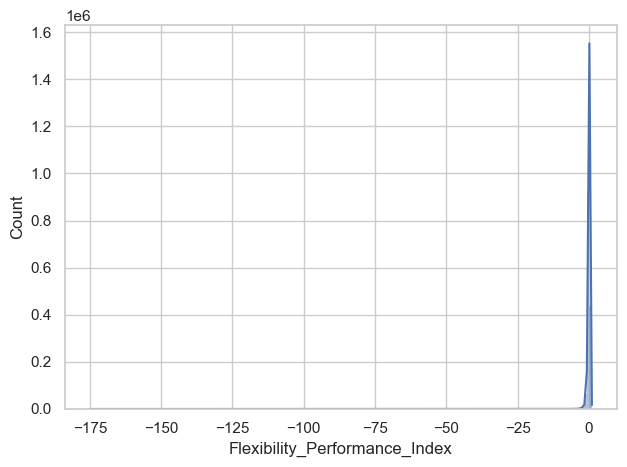

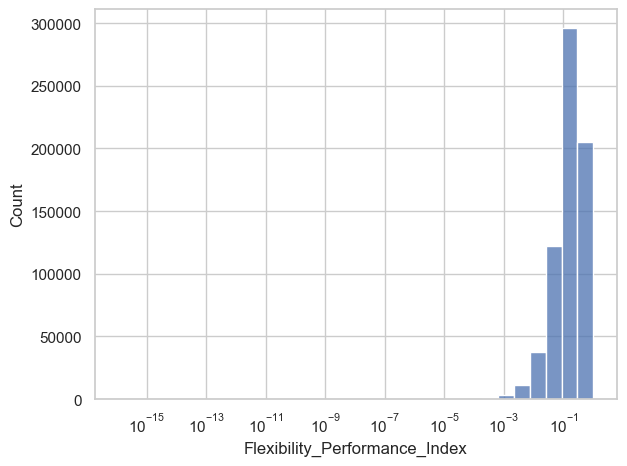

In [17]:
sns.histplot(data=df_fpi_hourly_experiment.to_pandas(), x="Flexibility_Performance_Index", bins=200, kde=True)
plt.show()

# log_series = (
#     df_fpi_hourly_experiment.select(
#         (pl.col("Flexibility_Performance_Index") + 1).log(base=10).alias("log10_col")
#     )
#     .drop_nulls()
#     .to_series()
# )

# sns.histplot(x=log_series, bins=30, kde=True)
# plt.xlabel("log10(col_name + 1)")
# plt.show()

pos_series = df_fpi_hourly_experiment.filter(pl.col("Flexibility_Performance_Index") > 0).get_column("Flexibility_Performance_Index")

sns.histplot(x=pos_series, bins=30, log_scale=True)
plt.show()

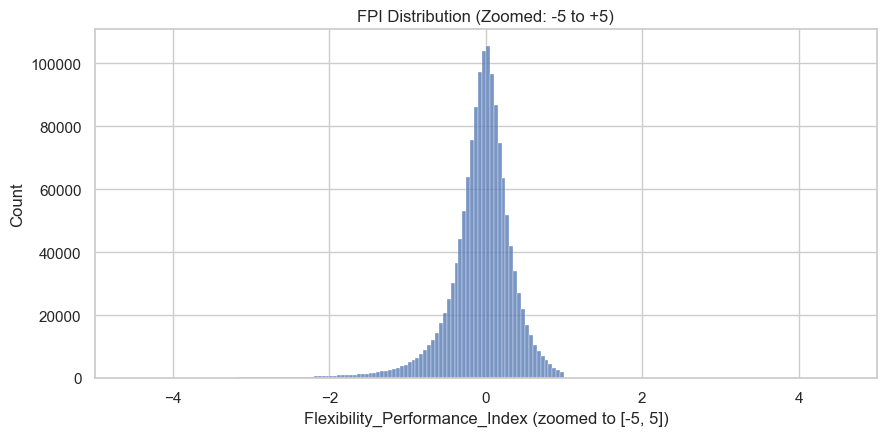

In [18]:
col = "Flexibility_Performance_Index"
fpi_zoom = (
    df_fpi_hourly_experiment.select(
        pl.col(col).filter(pl.col(col).is_between(-5.0, 5.0))
    )
    .get_column(col)
    .to_numpy()
)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(
    x=fpi_zoom, bins=200, binrange=(-5.0, 5.0), kde=False, ax=ax
)  # set kde=True if desired (slower on 1.45M rows)
ax.set_xlim(-5.0, 5.0)
ax.set_xlabel("Flexibility_Performance_Index (zoomed to [-5, 5])")
ax.set_title("FPI Distribution (Zoomed: -5 to +5)")
plt.tight_layout()
plt.show()

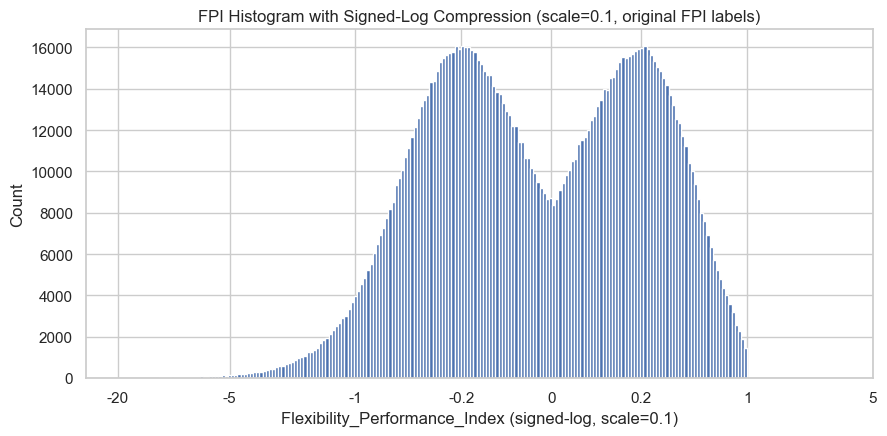

In [19]:
def signed_log_transform(x: np.ndarray, scale: float = 0.1) -> np.ndarray:
  """Signed log10 transform: sign(x) * log10(1 + |x| / scale). Handles negative values & 0."""
  if scale <= 0:
    raise ValueError(f"`scale` must be > 0, got {scale}")
  return np.sign(x) * np.log10(1.0 + np.abs(x) / scale)


def plot_fpi_signed_log_hist(
    df: pl.DataFrame,
    col: str = "Flexibility_Performance_Index",
    scale: float = 0.1,
    bins: int = 200,
    clip_range: tuple[float, float] | None = (-20.0, 5.0),
) -> None:
  expr = pl.col(col).drop_nulls()
  if clip_range is not None:
    lo, hi = clip_range
    expr = expr.filter(pl.col(col).is_between(lo, hi))

  fpi_raw = df.select(expr).get_column(col).to_numpy()
  fpi_t = signed_log_transform(fpi_raw, scale=scale)

  fig, ax = plt.subplots(figsize=(9, 4.5))
  ax.hist(fpi_t, bins=bins)

  # Choose meaningful original FPI ticks and map them into transformed x-coordinates
  candidate_ticks = np.array([-20.0, -5.0, -1.0, -0.2, 0.0, 0.2, 1.0, 5.0])
  if clip_range is not None:
    candidate_ticks = candidate_ticks[
        (candidate_ticks >= clip_range[0]) & (candidate_ticks <= clip_range[1])
    ]

  tick_positions = signed_log_transform(candidate_ticks, scale=scale)
  tick_labels = [f"{v:g}" for v in candidate_ticks]

  ax.set_xticks(tick_positions)
  ax.set_xticklabels(tick_labels)
  ax.set_xlabel(f"Flexibility_Performance_Index (signed-log, scale={scale})")
  ax.set_ylabel("Count")
  ax.set_title(
      f"FPI Histogram with Signed-Log Compression (scale={scale}, original FPI"
      " labels)"
  )
  plt.tight_layout()
  plt.show()


# Try adjusting `scale` (e.g., 0.05, 0.1, 0.5) and `clip_range` (or `None` for all non-null FPI)
plot_fpi_signed_log_hist(
    df_fpi_hourly_experiment, scale=0.1, bins=200, clip_range=(-20.0, 5.0)
)

In [20]:
def fpi_range_percentages(
    df: pl.DataFrame,
    fpi_col: str = "Flexibility_Performance_Index",
    id_col: str = "ID",
    low: float = -5.0,
    high: float = -1.0,
    clip_range: tuple[float, float] | None = (-20.0, 5.0),
) -> None:
  """Calculate percentage of households and rows in [low, high] (e.g., [-5.0, -1.0])."""
  if low > high:
    low, high = high, low

  base_df = df.filter(pl.col(fpi_col).is_not_null())
  if clip_range is not None:
    lo, hi = clip_range
    base_df = base_df.filter(pl.col(fpi_col).is_between(lo, hi))

  in_range_expr = pl.col(fpi_col).is_between(low, high)

  # 1) Row-level share (corresponds to area/counts in the histogram)
  row_stats = base_df.select(
      total_rows=pl.len(),
      in_range_rows=in_range_expr.sum(),
  ).with_columns(
      pct_of_rows=(pl.col("in_range_rows") / pl.col("total_rows")) * 100.0
  )

  # 2) Household-level share (unique `ID`s)
  hh_summary = base_df.group_by(id_col).agg(
      has_any_in_range=in_range_expr.any(),
      mean_fpi=pl.col(fpi_col).mean(),
      median_fpi=pl.col(fpi_col).median(),
  )

  hh_stats = hh_summary.select(
      total_households=pl.len(),
      households_any_in_range=pl.col("has_any_in_range").sum(),
      households_mean_in_range=pl.col("mean_fpi").is_between(low, high).sum(),
      households_median_in_range=pl.col("median_fpi").is_between(low, high).sum(),
  ).with_columns(
      pct_households_any=(
          pl.col("households_any_in_range") / pl.col("total_households")
      )
      * 100.0,
      pct_households_mean=(
          pl.col("households_mean_in_range") / pl.col("total_households")
      )
      * 100.0,
      pct_households_median=(
          pl.col("households_median_in_range") / pl.col("total_households")
      )
      * 100.0,
  )

  print(f"FPI Range: [{low}, {high}] | clip_range={clip_range}")
  print("\n--- Row / Histogram Share ---")
  print(row_stats)
  print("\n--- Household (`ID`) Share ---")
  print(hh_stats)


# Example usage matching your signed-log histogram:
fpi_range_percentages(
    df_fpi_hourly_experiment,
    fpi_col="Flexibility_Performance_Index",
    id_col="ID",
    low=-5.0,
    high=-1,
    clip_range=(-20.0, 5.0),  # Set to None to use all non-null FPI rows
)

FPI Range: [-5.0, -1] | clip_range=(-20.0, 5.0)

--- Row / Histogram Share ---
shape: (1, 3)
┌────────────┬───────────────┬─────────────┐
│ total_rows ┆ in_range_rows ┆ pct_of_rows │
│ ---        ┆ ---           ┆ ---         │
│ u32        ┆ u32           ┆ f64         │
╞════════════╪═══════════════╪═════════════╡
│ 1450817    ┆ 46476         ┆ 3.203436    │
└────────────┴───────────────┴─────────────┘

--- Household (`ID`) Share ---
shape: (1, 7)
┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ total_househ ┆ households_ ┆ households_ ┆ households_ ┆ pct_househo ┆ pct_househo ┆ pct_househo │
│ olds         ┆ any_in_rang ┆ mean_in_ran ┆ median_in_r ┆ lds_any     ┆ lds_mean    ┆ lds_median  │
│ ---          ┆ e           ┆ ge          ┆ ange        ┆ ---         ┆ ---         ┆ ---         │
│ u32          ┆ ---         ┆ ---         ┆ ---         ┆ f64         ┆ f64         ┆ f64         │
│              ┆ u32         ┆ u32       

In [21]:
# Examine FPI grouping ratios - below 0, 0, and above 0


In [22]:
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    display(df_fpi_hourly_experiment.head())

ID,From,Date,Day_Of_Week,Is_Weekend,Hour,Demand_kWh,Price_profile,Price_level,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72,Municipality,Region,Control_Price_Phase2,Group_Phase2,Which_Phases_Participate,ghi_Wh_m2,photons_m2,par_photons_m2,par_mol_m2,sun_minutes,Is_Zero,E_actual_peak,E_base_10_non_exp_same_hr,Prior_10_NonExp_SameHr_Temp,Prior_10_NonExp_SameHr_Count,Hourly_DOW_Adj_Factor,Hourly_Temp_Adj_Factor,E_base_peak,Prior_240h_Mean_Temp,Flexibility_Performance_Index,High_Flexibility_Flag
str,"datetime[ms, UTC]",date,i32,i32,i32,f64,cat,cat,f64,f64,f64,f64,f64,cat,cat,cat,cat,cat,f64,f64,f64,f64,i32,bool,f64,f64,f64,i32,f64,f64,f64,f64,f64,i32
"""Exp_1""",2020-12-16 00:00:00 UTC,2020-12-16,4,0,1,1.945,"""B""","""10""",1.0,7.1,7.6,8.0,6.2,"""Bergen""","""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,false,1.945,2.3145,5.49,10,1.0,1.0,2.3145,5.49,0.159646,1
"""Exp_1""",2020-12-16 01:00:00 UTC,2020-12-16,4,0,2,2.496,"""B""","""10""",0.99,7.4,7.6,7.9,6.3,"""Bergen""","""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,false,2.496,2.1382,5.75,10,1.0,1.0,2.1382,5.75,-0.167337,0
"""Exp_1""",2020-12-16 02:00:00 UTC,2020-12-16,4,0,3,1.866,"""B""","""10""",0.95,6.9,7.6,7.9,6.4,"""Bergen""","""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,false,1.866,2.2252,5.73,10,1.0,1.0,2.2252,5.73,0.161424,1
"""Exp_1""",2020-12-16 03:00:00 UTC,2020-12-16,4,0,4,1.875,"""B""","""10""",0.95,7.2,7.5,7.9,6.5,"""Bergen""","""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,false,1.875,2.2237,5.88,10,1.0,1.0,2.2237,5.88,0.156811,1
"""Exp_1""",2020-12-16 04:00:00 UTC,2020-12-16,4,0,5,2.46,"""B""","""10""",0.96,7.4,7.5,7.8,6.6,"""Bergen""","""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,false,2.46,2.0923,5.9,10,1.0,1.0,2.0923,5.9,-0.17574,0


In [23]:
# drop columns that are not useful or detrimental to our machine learning models
# Team Omega will test with E_base_peak not in the dataset, and with it avaialble - and measure for noise
cols_to_drop = ["Is_Weekend", 
                "Is_Zero", 
                "E_actual_peak",  
                "Demand_kWh", 
                "E_base_peak",
                "Region",
                "E_base_10_non_exp_same_hr",
                "Prior_10_NonExp_SameHr_Temp",
                "Prior_10_NonExp_SameHr_Count",
                "Hourly_DOW_Adj_Factor",
                "Hourly_Temp_Adj_Factor",
]
df_fpi_hourly_experiment_columns_removed = df_fpi_hourly_experiment.drop(cols_to_drop)#, strict=False) # strict=False lets us remove future columns without re-running the whole notebook
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    print(f"Rows (all): {df_fpi_hourly_experiment_columns_removed.height:,} | Columns: {df_fpi_hourly_experiment_columns_removed.width}")
    display(df_fpi_hourly_experiment_columns_removed.head())

Rows (all): 1,450,947 | Columns: 24


ID,From,Date,Day_Of_Week,Hour,Price_profile,Price_level,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72,Municipality,Control_Price_Phase2,Group_Phase2,Which_Phases_Participate,ghi_Wh_m2,photons_m2,par_photons_m2,par_mol_m2,sun_minutes,Prior_240h_Mean_Temp,Flexibility_Performance_Index,High_Flexibility_Flag
str,"datetime[ms, UTC]",date,i32,i32,cat,cat,f64,f64,f64,f64,f64,cat,cat,cat,cat,f64,f64,f64,f64,i32,f64,f64,i32
"""Exp_1""",2020-12-16 00:00:00 UTC,2020-12-16,4,1,"""B""","""10""",1.0,7.1,7.6,8.0,6.2,"""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,5.49,0.159646,1
"""Exp_1""",2020-12-16 01:00:00 UTC,2020-12-16,4,2,"""B""","""10""",0.99,7.4,7.6,7.9,6.3,"""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,5.75,-0.167337,0
"""Exp_1""",2020-12-16 02:00:00 UTC,2020-12-16,4,3,"""B""","""10""",0.95,6.9,7.6,7.9,6.4,"""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,5.73,0.161424,1
"""Exp_1""",2020-12-16 03:00:00 UTC,2020-12-16,4,4,"""B""","""10""",0.95,7.2,7.5,7.9,6.5,"""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,5.88,0.156811,1
"""Exp_1""",2020-12-16 04:00:00 UTC,2020-12-16,4,5,"""B""","""10""",0.96,7.4,7.5,7.8,6.6,"""Bergen""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,5.9,-0.17574,0


In [24]:
def _is_categorical_or_string(dtype: pl.DataType) -> bool:
    """Safely detect parameterized Polars Categorical dtypes as well as String/Utf8."""
    return isinstance(dtype, pl.Categorical) or dtype in (pl.String, pl.Utf8)


def _is_numeric(dtype: pl.DataType) -> bool:
    """Detect standard numeric Polars dtypes (excluding booleans)."""
    return isinstance(
        dtype,
        (
            pl.Int8, pl.Int16, pl.Int32, pl.Int64,
            pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64,
            pl.Float32, pl.Float64,
        ),
    )


def preprocess_and_split_polars(
    df: pl.DataFrame,
    robust_scaler_cols: Optional[list[str]] = None,
    ohe_cols: Optional[list[str]] = None,
    ignore_cols: Optional[list[str]] = None,
    remove_cols: Optional[list[str]] = None,
    mode: Literal["supervised", "unsupervised"] = "supervised",
    split_pcts: list[int] = [70, 15, 15],
    split_mode: Literal["time", "random", "group"] = "time",
    group_col: Optional[str] = "ID",
    scaling_mode: Literal["robust", "none", "keep_raw"] = "robust",
    ohe_mode: Literal["encode", "none"] = "encode",
    time_cols: list[str] = ["From", "Date", "Hour"],
    random_state: int = 42,
    drop_ohe_original: bool = True,
    keep_row_id: bool = True,
    return_artifacts: bool = False,
) -> Union[
    pl.DataFrame,
    Tuple[pl.DataFrame, pl.DataFrame],
    Tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame],
    Tuple[
        Union[pl.DataFrame, Tuple[pl.DataFrame, pl.DataFrame], Tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame]],
        Dict[str, Any],
    ],
]:
    """
    Preprocess a Polars DataFrame with RobustScaler + OneHotEncoder and either:
      - mode="supervised"   : Split into 2 (train/test) or 3 (train/val/test) splits
                            and fit transformers strictly on the training split.
      - mode="unsupervised" : Keep 100% of rows (no split) for unsupervised models
                            such as K-Means clustering, PCA, HDBSCAN, GMM, etc.

    Parameters
    ----------
    df : pl.DataFrame
        Input Polars DataFrame (e.g., df_fpi_hourly_experiment).
    robust_scaler_cols : list[str] | None
        Columns to scale with RobustScaler. If None, inferred from numeric dtypes
        (excluding ignore_cols, remove_cols, and ohe_cols).
    ohe_cols : list[str] | None
        Columns to one-hot encode. If None, inferred from Categorical/String dtypes
        (excluding ignore_cols and remove_cols).
    ignore_cols : list[str] | None
        Columns to leave untouched in the returned splits (e.g., IDs, timestamps, targets, raw flags).
    remove_cols : list[str] | None
        Columns to remove from the modeling splits prior to preprocessing/splitting,
        while capturing them per split (keyed by `_row_id`) in `artifacts["removed_cols_by_split"]`
        so they can be re-connected later via `.join(..., on="_row_id", how="left")`.
    mode : {"supervised", "unsupervised"}
        "supervised" splits data and fits transformers on train only.
        "unsupervised" returns the full 100% preprocessed DataFrame without splitting.
    split_pcts : list[int]
        Integer percentages summing to 100 (used when mode="supervised").
        Length 2 -> (train, test); Length 3 -> (train, val, test). Default is [70, 15, 15].
    split_mode : {"time", "random", "group"}
        "time" sorts chronologically before slicing.
        "random" shuffles rows reproducibly using `random_state`.
        "group" splits by `group_col` (e.g., "ID") using GroupShuffleSplit so groups
        do not leak across train/val/test.
    group_col : str | None
        Column name used for household/group-aware splitting when split_mode="group".
    time_cols : list[str]
        Columns used for chronological sorting when split_mode="time".
    random_state : int
        Seed for reproducible shuffling/group splitting.
    drop_ohe_original : bool
        If True, replaces original ohe_cols with encoded indicator columns.
    keep_row_id : bool
        If True, keeps `_row_id` on returned split DataFrames so removed columns (or
        original rows) can be joined back on `_row_id`. If False, drops `_row_id`
        from the returned splits.
    return_artifacts : bool
        If True, also returns a dict with the fitted preprocessor, column lists,
        and captured `removed_cols_by_split`.
    scaling_mode options:
      - "robust"   : Fit RobustScaler on train (or full df in unsupervised mode) and replace numeric cols.
      - "none"     : Skip RobustScaler (ideal for tree ensembles like Random Forest / XGBoost).
      - "keep_raw" : Fit RobustScaler, append scaled cols, and keep raw numeric cols.
    ohe_mode options:
      - "encode"   : Fit OneHotEncoder on train (or full df in unsupervised mode) and add OHE columns.
      - "none"     : Skip OneHotEncoder and keep categorical columns as-is (ideal for tree/GB models).
    """
    # --- 1. Validate mode, split_pcts, scaling_mode, ohe_mode & column args ---
    if mode not in ("supervised", "unsupervised"):
        raise ValueError("`mode` must be either 'supervised' or 'unsupervised'.")
    if scaling_mode not in ("robust", "none", "keep_raw"):
        raise ValueError("`scaling_mode` must be one of 'robust', 'none', or 'keep_raw'.")
    if ohe_mode not in ("encode", "none"):
        raise ValueError("`ohe_mode` must be either 'encode' or 'none'.")

    if mode == "supervised":
        if not isinstance(split_pcts, list) or len(split_pcts) not in (2, 3):
            raise ValueError("`split_pcts` must be a list of 2 integers [train, test] or 3 integers [train, val, test].")
        if not all(isinstance(p, int) and not isinstance(p, bool) and p > 0 for p in split_pcts):
            raise ValueError("All elements in `split_pcts` must be positive integers.")
        if sum(split_pcts) != 100:
            raise ValueError(f"`split_pcts` must sum to 100, got {sum(split_pcts)} ({split_pcts}).")

    row_id_col = "_row_id"
    if row_id_col in df.columns:
        raise ValueError(f"Input DataFrame already contains reserved column '{row_id_col}'.")

    ignored = set(ignore_cols or [])
    missing_ignored = ignored - set(df.columns)
    if missing_ignored:
        raise ValueError(f"`ignore_cols` contains columns not in DataFrame: {sorted(missing_ignored)}")

    removed_list = list(dict.fromkeys(remove_cols or []))
    missing_removed = set(removed_list) - set(df.columns)
    if missing_removed:
        raise ValueError(f"`remove_cols` contains columns not in DataFrame: {sorted(missing_removed)}")

    # Prevent conflicting instructions on the same column
    overlap_ignore_remove = ignored & set(removed_list)
    if overlap_ignore_remove:
        raise ValueError(f"Columns cannot be in both `ignore_cols` and `remove_cols`: {sorted(overlap_ignore_remove)}")

    removed_set = set(removed_list)
    excluded_from_features = ignored | removed_set

    # Attach a deterministic row ID prior to ordering/splitting so removed columns can be re-linked later
    df_indexed = df.with_row_index(name=row_id_col)

    # --- 2. Infer categorical & numeric feature columns ---
    if ohe_cols is None:
        inferred_ohe_cols = [
            col for col, dtype in df.schema.items()
            if col not in excluded_from_features and _is_categorical_or_string(dtype)
        ]
        print(f'Infered OHE: {inferred_ohe_cols}')
    else:
        missing_ohe = set(ohe_cols) - set(df.columns)
        if missing_ohe:
            raise ValueError(f"`ohe_cols` contains columns not in DataFrame: {sorted(missing_ohe)}")
        inferred_ohe_cols = [c for c in ohe_cols if c not in excluded_from_features]

    overlap = set(inferred_ohe_cols) & (set(robust_scaler_cols or []))
    if overlap:
        raise ValueError(f"Columns cannot be in both `ohe_cols` and `robust_scaler_cols`: {sorted(overlap)}")

    if robust_scaler_cols is None:
        inferred_num_cols = [
            col for col, dtype in df.schema.items()
            if col not in excluded_from_features and col not in inferred_ohe_cols and _is_numeric(dtype)
        ]
        print(f'Infered Num: {inferred_num_cols}')
    else:
        missing_num = set(robust_scaler_cols) - set(df.columns)
        if missing_num:
            raise ValueError(f"`robust_scaler_cols` contains columns not in DataFrame: {sorted(missing_num)}")
        inferred_num_cols = [c for c in robust_scaler_cols if c not in excluded_from_features and c not in inferred_ohe_cols]

    active_num_cols = inferred_num_cols if scaling_mode in ("robust", "keep_raw") else []
    active_ohe_cols = inferred_ohe_cols if ohe_mode == "encode" else []

    # --- 3. Order & split data (or keep 100% in unsupervised mode) ---
    if mode == "unsupervised":
        sort_by = [c for c in time_cols if c in df_indexed.columns]
        raw_splits = [df_indexed.sort(sort_by) if sort_by else df_indexed]
        fit_source_df = raw_splits[0]
        split_names = ["full"]
    else:
        if split_mode == "time":
            sort_by = [c for c in time_cols if c in df_indexed.columns]
            working_df = df_indexed.sort(sort_by) if sort_by else df_indexed
            n_rows = working_df.height
            if n_rows < len(split_pcts):
                raise ValueError("DataFrame has fewer rows than requested splits.")

            if len(split_pcts) == 3:
                train_pct, val_pct, _ = split_pcts
                n_train = int(n_rows * (train_pct / 100.0))
                n_val = int(n_rows * (val_pct / 100.0))
                raw_splits = [
                    working_df.slice(0, n_train),
                    working_df.slice(n_train, n_val),
                    working_df.slice(n_train + n_val, n_rows - n_train - n_val),
                ]
                split_names = ["train", "val", "test"]
            else:
                train_pct, _ = split_pcts
                n_train = int(n_rows * (train_pct / 100.0))
                raw_splits = [
                    working_df.slice(0, n_train),
                    working_df.slice(n_train, n_rows - n_train),
                ]
                split_names = ["train", "test"]

        elif split_mode == "random":
            working_df = df_indexed.sample(fraction=1.0, shuffle=True, seed=random_state)
            n_rows = working_df.height
            if n_rows < len(split_pcts):
                raise ValueError("DataFrame has fewer rows than requested splits.")

            if len(split_pcts) == 3:
                train_pct, val_pct, _ = split_pcts
                n_train = int(n_rows * (train_pct / 100.0))
                n_val = int(n_rows * (val_pct / 100.0))
                raw_splits = [
                    working_df.slice(0, n_train),
                    working_df.slice(n_train, n_val),
                    working_df.slice(n_train + n_val, n_rows - n_train - n_val),
                ]
                split_names = ["train", "val", "test"]
            else:
                train_pct, _ = split_pcts
                n_train = int(n_rows * (train_pct / 100.0))
                raw_splits = [
                    working_df.slice(0, n_train),
                    working_df.slice(n_train, n_rows - n_train),
                ]
                split_names = ["train", "test"]

        elif split_mode == "group":
            if not group_col or group_col not in df_indexed.columns:
                raise ValueError(f"`group_col` ('{group_col}') must be a valid column in DataFrame when split_mode='group'.")

            row_idx = np.arange(df_indexed.height)
            groups = df_indexed.get_column(group_col).to_numpy()

            if len(split_pcts) == 3:
                train_pct, val_pct, test_pct = split_pcts
                test_frac = test_pct / 100.0
                val_frac_of_remaining = val_pct / (train_pct + val_pct)

                gss_test = GroupShuffleSplit(n_splits=1, test_size=test_frac, random_state=random_state)
                train_val_idx, test_idx = next(gss_test.split(row_idx, groups=groups))

                gss_val = GroupShuffleSplit(n_splits=1, test_size=val_frac_of_remaining, random_state=random_state)
                train_rel_idx, val_rel_idx = next(gss_val.split(train_val_idx, groups=groups[train_val_idx]))
                train_idx = train_val_idx[train_rel_idx]
                val_idx = train_val_idx[val_rel_idx]

                raw_splits = [
                    df_indexed[train_idx.tolist()],
                    df_indexed[val_idx.tolist()],
                    df_indexed[test_idx.tolist()],
                ]
                split_names = ["train", "val", "test"]
            else:
                train_pct, test_pct = split_pcts
                gss = GroupShuffleSplit(n_splits=1, test_size=test_pct / 100.0, random_state=random_state)
                train_idx, test_idx = next(gss.split(row_idx, groups=groups))
                raw_splits = [
                    df_indexed[train_idx.tolist()],
                    df_indexed[test_idx.tolist()],
                ]
                split_names = ["train", "test"]
        else:
            raise ValueError("`split_mode` must be 'time', 'random', or 'group'.")

        # Fit strictly on training split to prevent leakage
        fit_source_df = raw_splits[0]

    # --- 4. Capture remove_cols per split (with _row_id) and drop from splits ---
    removed_cols_by_split: Dict[str, pl.DataFrame] = {}
    splits_without_removed: list[pl.DataFrame] = []

    for split_name, split_df in zip(split_names, raw_splits):
        if removed_list:
            removed_cols_by_split[split_name] = split_df.select([row_id_col] + removed_list)
            splits_without_removed.append(split_df.drop(removed_list))
        else:
            # Still store _row_id mapping so callers can always look up row order/IDs if desired
            removed_cols_by_split[split_name] = split_df.select([row_id_col])
            splits_without_removed.append(split_df)

    fit_source_df = splits_without_removed[0]

    # --- 5. Fit transformers on training split (or full df in unsupervised mode) ---
    cols_to_fit = active_num_cols + active_ohe_cols
    print(f'Columns Transformed: {cols_to_fit}')
    transformed_splits: list[pl.DataFrame] = []
    preprocessor: Optional[ColumnTransformer] = None
    encoded_col_names: list[str] = []

    if cols_to_fit:
        transformers = []
        if active_num_cols:
            transformers.append(("num", RobustScaler(), active_num_cols))
        if active_ohe_cols:
            transformers.append((
                "cat",
                OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop=None),  # drop options {'first', 'if_binary'} for unregularized linear/logistic regression
                active_ohe_cols,
            ))

        preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

        fit_pd = fit_source_df.select(cols_to_fit).to_pandas()
        for c in active_ohe_cols:
            fit_pd[c] = fit_pd[c].astype(str)

        preprocessor.fit(fit_pd)
        encoded_col_names = preprocessor.get_feature_names_out().tolist()

        for split_df in splits_without_removed:
            split_pd = split_df.select(cols_to_fit).to_pandas()
            for c in active_ohe_cols:
                split_pd[c] = split_pd[c].astype(str)

            arr = preprocessor.transform(split_pd)
            if hasattr(arr, "toarray"):
                arr = arr.toarray()
            elif hasattr(arr, "to_numpy"):
                arr = arr.to_numpy()

            transformed_pl = pl.DataFrame({
                name: arr[:, idx] for idx, name in enumerate(encoded_col_names)
            })

            cols_to_drop_from_base = []
            if drop_ohe_original and active_ohe_cols:
                cols_to_drop_from_base.extend(active_ohe_cols)
            if scaling_mode == "robust" and active_num_cols:
                cols_to_drop_from_base.extend(active_num_cols)

            base_pl = split_df.drop(cols_to_drop_from_base) if cols_to_drop_from_base else split_df
            merged_pl = pl.concat([base_pl, transformed_pl], how="horizontal")
            if not keep_row_id:
                merged_pl = merged_pl.drop(row_id_col)
            transformed_splits.append(merged_pl)
    else:
        for split_df in splits_without_removed:
            transformed_splits.append(split_df if keep_row_id else split_df.drop(row_id_col))

    result_payload: Union[
        pl.DataFrame,
        Tuple[pl.DataFrame, pl.DataFrame],
        Tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame],
    ] = transformed_splits[0] if mode == "unsupervised" else tuple(transformed_splits)

    if return_artifacts:
        artifacts = {
            "preprocessor": preprocessor,
            "detected_num_cols": inferred_num_cols,
            "scaled_num_cols": active_num_cols,
            "ohe_cols": inferred_ohe_cols,
            "encoded_ohe_cols": active_ohe_cols,
            "encoded_feature_names": encoded_col_names,
            "ignored_cols": sorted(ignored),
            "removed_cols": removed_list,
            "removed_cols_by_split": removed_cols_by_split,
            "row_id_col": row_id_col if keep_row_id else None,
            "scaling_mode": scaling_mode,
            "ohe_mode": ohe_mode,
            "mode": mode,
            "split_mode": None if mode == "unsupervised" else split_mode,
            "group_col": group_col if split_mode == "group" else None,
            "split_names": split_names,
        }
        return result_payload, artifacts

    return result_payload



""" # Reconnect removed columns (e.g., ID, From, Date, targets) to test predictions/results
test_with_removed = df_test.join(
    artifacts["removed_cols_by_split"]["test"],
    on="_row_id",
    how="left",
)

# Or reconnect inside a GroupKFold validation slice using val_idx
val_slice_with_removed = (
    df_train[val_idx.tolist()]
    .join(artifacts["removed_cols_by_split"]["train"], on="_row_id", how="left")
) """

' # Reconnect removed columns (e.g., ID, From, Date, targets) to test predictions/results\ntest_with_removed = df_test.join(\n    artifacts["removed_cols_by_split"]["test"],\n    on="_row_id",\n    how="left",\n)\n\n# Or reconnect inside a GroupKFold validation slice using val_idx\nval_slice_with_removed = (\n    df_train[val_idx.tolist()]\n    .join(artifacts["removed_cols_by_split"]["train"], on="_row_id", how="left")\n) '

In [37]:
def build_fold_preprocessor(
    num_cols: List[str],
    ohe_cols: List[str],
    scaling_mode: Literal["robust", "none"] = "robust",
    ohe_mode: Literal["encode", "none"] = "encode",
) -> Optional[ColumnTransformer]:
  """Build a fresh, unfitted ColumnTransformer for a single CV fold or final train fit."""
  transformers = []
  if scaling_mode == "robust" and num_cols:
    transformers.append(("num", RobustScaler(), num_cols))
  if ohe_mode == "encode" and ohe_cols:
    transformers.append((
        "cat",
        OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop=None),
        ohe_cols,
    ))
  if not transformers:
    return None
  return ColumnTransformer(transformers=transformers, remainder="drop")


def iter_group_kfold_preprocessed(
    df_train_raw: pl.DataFrame,
    df_test_raw: pl.DataFrame,
    target_col: str,
    groups: np.ndarray,
    num_cols: List[str],
    ohe_cols: List[str],
    scaling_mode: Literal["robust", "none"] = "robust",
    ohe_mode: Literal["encode", "none"] = "encode",
    n_splits: int = 5,
) -> Iterator[Dict[str, Any]]:
  """
    Yield fold-by-fold arrays for both transformed (linear/NN) and untransformed
    (tree/GB, via scaling_mode='none', ohe_mode='none') pipelines using GroupKFold.
    """
  feature_cols = num_cols + ohe_cols
  print(f'K-Fold Features: {feature_cols}')
  y_train_all = df_train_raw.get_column(target_col).to_numpy()
  y_test = df_test_raw.get_column(target_col).to_numpy()

  use_preprocessor = bool(
      (scaling_mode == "robust" and num_cols)
      or (ohe_mode == "encode" and ohe_cols)
  )

  if use_preprocessor:
    X_train_pd = df_train_raw.select(feature_cols).to_pandas()
    X_test_pd = df_test_raw.select(feature_cols).to_pandas()
    for c in ohe_cols:
      X_train_pd[c] = X_train_pd[c].astype(str)
      X_test_pd[c] = X_test_pd[c].astype(str)
    split_input = X_train_pd
  else:
    X_train_raw_np = df_train_raw.select(feature_cols).to_numpy()
    X_test_raw_np = df_test_raw.select(feature_cols).to_numpy()
    split_input = X_train_raw_np

  gkf = GroupKFold(n_splits=n_splits)
  for fold, (tr_idx, val_idx) in enumerate(
      gkf.split(split_input, y_train_all, groups=groups), start=1
  ):
    if use_preprocessor:
      preprocessor = build_fold_preprocessor(
          num_cols=num_cols,
          ohe_cols=ohe_cols,
          scaling_mode=scaling_mode,
          ohe_mode=ohe_mode,
      )
      X_tr = preprocessor.fit_transform(X_train_pd.iloc[tr_idx])
      X_va = preprocessor.transform(X_train_pd.iloc[val_idx])
      X_te = preprocessor.transform(X_test_pd)
      feat_names = preprocessor.get_feature_names_out().tolist()
    else:
      preprocessor = None
      X_tr = X_train_raw_np[tr_idx]
      X_va = X_train_raw_np[val_idx]
      X_te = X_test_raw_np
      feat_names = feature_cols

    yield {
        "fold": fold,
        "tr_idx": tr_idx,
        "val_idx": val_idx,
        "X_tr": X_tr,
        "y_tr": y_train_all[tr_idx],
        "X_va": X_va,
        "y_va": y_train_all[val_idx],
        "X_test": X_te,
        "y_test": y_test,
        "preprocessor": preprocessor,
        "feature_names": feat_names,
    }

In [38]:
ignore_cols_regression = [
    "Flexibility_Performance_Index",
]

remove_cols_regression = [
    "ID",
    "From",
    "Date",
    "High_Flexibility_Flag",
]

target_col = "Flexibility_Performance_Index"

# 1) Supervised 80/20 Household-Aware Split (kept raw so preprocessing happens in-fold)
(df_train_linear_nn_regression, df_test_linear_nn_regression), (
    artifacts_linear_nn_regression
) = preprocess_and_split_polars(
    df=df_fpi_hourly_experiment_columns_removed,
    ignore_cols=ignore_cols_regression,
    remove_cols=remove_cols_regression,
    mode="supervised",
    split_pcts=[80, 20],
    split_mode="group",
    group_col="ID",
    scaling_mode="none",
    ohe_mode="none",
    random_state=42,
    return_artifacts=True,
)

num_cols_reg = artifacts_linear_nn_regression["detected_num_cols"]
ohe_cols_reg = artifacts_linear_nn_regression["ohe_cols"]
feature_cols_reg = num_cols_reg + ohe_cols_reg
groups_train_reg = (
    artifacts_linear_nn_regression["removed_cols_by_split"]["train"]
    .get_column("ID")
    .to_numpy()
)

# 2) Linear & Neural Net Regression: 5-Fold GroupKFold with In-Fold RobustScaler + OHE
linear_nn_regression_folds = list(
    iter_group_kfold_preprocessed(
        df_train_raw=df_train_linear_nn_regression,
        df_test_raw=df_test_linear_nn_regression,
        target_col=target_col,
        groups=groups_train_reg,
        num_cols=num_cols_reg,
        ohe_cols=ohe_cols_reg,
        scaling_mode="robust",
        ohe_mode="encode",
        n_splits=5,
    )
)

print(f'Shape of df_train_linear_nn_regression: {df_train_linear_nn_regression.shape}')

for fold_data in linear_nn_regression_folds:
  print(
      f"Linear & Neural Net Regression k-Fold {fold_data['fold']}: "
      f"train={fold_data['X_tr'].shape}, val={fold_data['X_va'].shape},"
      f" test={fold_data['X_test'].shape}"
  )

X_train_full_linear_nn_regression = df_train_linear_nn_regression.select(
    feature_cols_reg
).to_numpy()
y_train_reg_linear_nn_regression = df_train_linear_nn_regression.get_column(
    target_col
).to_numpy()

# 3) GB & Tree-Ensemble Regression: Reuse raw group split + unified iter_group_kfold_preprocessed
df_train_tree_boost_regression = df_train_linear_nn_regression
df_test_tree_boost_regression = df_test_linear_nn_regression
artifacts_tree_boost_regression = artifacts_linear_nn_regression

tree_boost_regression_folds = list(
    iter_group_kfold_preprocessed(
        df_train_raw=df_train_tree_boost_regression,
        df_test_raw=df_test_tree_boost_regression,
        target_col=target_col,
        groups=groups_train_reg,
        num_cols=num_cols_reg,
        ohe_cols=ohe_cols_reg,
        scaling_mode="none",
        ohe_mode="none",
        n_splits=5,
    )
)

for fold_data in tree_boost_regression_folds:
  print(
      f"GB & Tree-Ensemble Regression k-Fold {fold_data['fold']}: "
      f"train rows={len(fold_data['tr_idx']):,},"
      f" val rows={len(fold_data['val_idx']):,}"
  )

X_train_full_tree_boost_regression = df_train_tree_boost_regression.select(
    feature_cols_reg
).to_numpy()
y_train_reg_tree_boost_regression = df_train_tree_boost_regression.get_column(
    target_col
).to_numpy()

remove_cols_unsupervised = [
    "ID",
    "From",
    "Date",
    "Flexibility_Performance_Index",
    "High_Flexibility_Flag",
]

# 4) Unsupervised (100% Data, No Split) for K-Means Clustering
df_unsupervised, artifacts_unsupervised = preprocess_and_split_polars(
    df=df_fpi_hourly_experiment_columns_removed,
    ignore_cols=None,
    remove_cols=remove_cols_unsupervised,
    mode="unsupervised",
    scaling_mode="robust",
    ohe_mode="encode",
    return_artifacts=True,
)

Infered OHE: ['Price_profile', 'Price_level', 'Municipality', 'Control_Price_Phase2', 'Group_Phase2', 'Which_Phases_Participate']
Infered Num: ['Day_Of_Week', 'Hour', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72', 'ghi_Wh_m2', 'photons_m2', 'par_photons_m2', 'par_mol_m2', 'sun_minutes', 'Prior_240h_Mean_Temp']
Columns Transformed: []
K-Fold Features: ['Day_Of_Week', 'Hour', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72', 'ghi_Wh_m2', 'photons_m2', 'par_photons_m2', 'par_mol_m2', 'sun_minutes', 'Prior_240h_Mean_Temp', 'Price_profile', 'Price_level', 'Municipality', 'Control_Price_Phase2', 'Group_Phase2', 'Which_Phases_Participate']
Shape of df_train_linear_nn_regression: (1160562, 21)
Linear & Neural Net Regression k-Fold 1: train=(928230, 50), val=(232332, 50), test=(290385, 50)
Linear & Neural Net Regression k-Fold 2: train=(928230, 50), val=(232332, 50), test=(290385, 50)
Linear & Neural Net 

In [27]:
ignore_cols_classification = [
    "High_Flexibility_Flag",
]

remove_cols_classification = [
    "ID",
    "From",
    "Date",
    "Flexibility_Performance_Index",
]

target_col_clf = "High_Flexibility_Flag"

# 1) CLASSIFICATION Supervised 80/20 Household-Aware Split (kept raw for in-fold fit)
(df_train_linear_nn_classification, df_test_linear_nn_classification), (
    artifacts_linear_nn_classification
) = preprocess_and_split_polars(
    df=df_fpi_hourly_experiment_columns_removed,
    ignore_cols=ignore_cols_classification,
    remove_cols=remove_cols_classification,
    mode="supervised",
    split_pcts=[80, 20],
    split_mode="group",
    group_col="ID",
    scaling_mode="none",
    ohe_mode="none",
    random_state=42,
    return_artifacts=True,
)

num_cols_clf = artifacts_linear_nn_classification["detected_num_cols"]
ohe_cols_clf = artifacts_linear_nn_classification["ohe_cols"]
feature_cols_clf = num_cols_clf + ohe_cols_clf
groups_train_clf = (
    artifacts_linear_nn_classification["removed_cols_by_split"]["train"]
    .get_column("ID")
    .to_numpy()
)

# 2) Linear & Neural Net Classification: 5-Fold GroupKFold with In-Fold RobustScaler + OHE
linear_nn_classification_folds = list(
    iter_group_kfold_preprocessed(
        df_train_raw=df_train_linear_nn_classification,
        df_test_raw=df_test_linear_nn_classification,
        target_col=target_col_clf,
        groups=groups_train_clf,
        num_cols=num_cols_clf,
        ohe_cols=ohe_cols_clf,
        scaling_mode="robust",
        ohe_mode="encode",
        n_splits=5,
    )
)

for fold_data in linear_nn_classification_folds:
  print(
      f"Linear & Neural Net Classification k-Fold {fold_data['fold']}: "
      f"train={fold_data['X_tr'].shape}, val={fold_data['X_va'].shape},"
      f" test={fold_data['X_test'].shape}"
  )

X_train_full_linear_nn_classification = (
    df_train_linear_nn_classification.select(feature_cols_clf).to_numpy()
)
y_train_clf_linear_nn_classification = (
    df_train_linear_nn_classification.get_column(target_col_clf).to_numpy()
)

# 3) GB & Tree-Ensemble Classification: Reuse raw group split + unified iter_group_kfold_preprocessed
df_train_tree_boost_classification = df_train_linear_nn_classification
df_test_tree_boost_classification = df_test_linear_nn_classification
artifacts_tree_boost_classification = artifacts_linear_nn_classification

tree_boost_classification_folds = list(
    iter_group_kfold_preprocessed(
        df_train_raw=df_train_tree_boost_classification,
        df_test_raw=df_test_tree_boost_classification,
        target_col=target_col_clf,
        groups=groups_train_clf,
        num_cols=num_cols_clf,
        ohe_cols=ohe_cols_clf,
        scaling_mode="none",
        ohe_mode="none",
        n_splits=5,
    )
)

for fold_data in tree_boost_classification_folds:
  print(
      f"GB & Tree-Ensemble Classification k-Fold {fold_data['fold']}: "
      f"train rows={len(fold_data['tr_idx']):,},"
      f" val rows={len(fold_data['val_idx']):,}"
  )

X_train_full_tree_boost_classification = (
    df_train_tree_boost_classification.select(feature_cols_clf).to_numpy()
)
y_train_clf_tree_boost_classification = (
    df_train_tree_boost_classification.get_column(target_col_clf).to_numpy()
)

Infered OHE: ['Price_profile', 'Price_level', 'Municipality', 'Control_Price_Phase2', 'Group_Phase2', 'Which_Phases_Participate']
Infered Num: ['Day_Of_Week', 'Hour', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72', 'ghi_Wh_m2', 'photons_m2', 'par_photons_m2', 'par_mol_m2', 'sun_minutes', 'Prior_240h_Mean_Temp']
Columns Transformed: []
Linear & Neural Net Classification k-Fold 1: train=(928230, 50), val=(232332, 50), test=(290385, 50)
Linear & Neural Net Classification k-Fold 2: train=(928230, 50), val=(232332, 50), test=(290385, 50)
Linear & Neural Net Classification k-Fold 3: train=(928612, 50), val=(231950, 50), test=(290385, 50)
Linear & Neural Net Classification k-Fold 4: train=(928588, 50), val=(231974, 50), test=(290385, 50)
Linear & Neural Net Classification k-Fold 5: train=(928588, 50), val=(231974, 50), test=(290385, 50)
GB & Tree-Ensemble Classification k-Fold 1: train rows=928,230, val rows=232,332
GB & Tree-Ensemble Classificati

In [28]:
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    print(f"Rows (all): {df_unsupervised.height:,} | Columns: {df_unsupervised.width}")
    display(df_unsupervised.head())

Rows (all): 1,450,947 | Columns: 51


_row_id,num__Day_Of_Week,num__Hour,num__Experiment_price_NOK_kWh,num__Temperature,num__Temperature24,num__Temperature48,num__Temperature72,num__ghi_Wh_m2,num__photons_m2,num__par_photons_m2,num__par_mol_m2,num__sun_minutes,num__Prior_240h_Mean_Temp,cat__Price_profile_A,cat__Price_profile_B,cat__Price_profile_C,cat__Price_profile_P,cat__Price_profile_P0,cat__Price_level_10,cat__Price_level_15,cat__Price_level_2,cat__Price_level_30,cat__Price_level_5,cat__Price_level_5_10,cat__Municipality_Asker,cat__Municipality_Bergen,cat__Municipality_Bodø,cat__Municipality_Bærum,cat__Municipality_Drammen,cat__Municipality_Lillestrøm,cat__Municipality_Oslo,cat__Municipality_Stavanger,cat__Municipality_Tromsø,cat__Municipality_Trondheim,cat__Control_Price_Phase2_Price group,cat__Group_Phase2_Ber_1,cat__Group_Phase2_Bo_1,cat__Group_Phase2_H1,cat__Group_Phase2_H2,cat__Group_Phase2_Os_1,cat__Group_Phase2_Os_2,cat__Group_Phase2_Os_3,cat__Group_Phase2_Os_4,cat__Group_Phase2_Os_5,cat__Group_Phase2_Os_6,cat__Group_Phase2_Trom_1,cat__Group_Phase2_Trom_2,cat__Group_Phase2_Trond_1,cat__Which_Phases_Participate_Both,cat__Which_Phases_Participate_Phase_2
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
346401,0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
885714,0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
248145,0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
486582,0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
675672,0.0,-0.916667,-0.024814,1.852459,1.732394,1.736842,1.467532,0.0,0.0,0.0,0.0,0.0,1.608225,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [39]:
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    print(f"Rows (all): {df_train_linear_nn_regression.height:,} | Columns: {df_train_linear_nn_regression.width}")
    display(df_train_linear_nn_regression.head())
    print(f'Shape of X_train: {X_train_full_linear_nn_regression.shape}')
    print(f'Shape of Y_train: {y_train_reg_linear_nn_regression.shape}')

Rows (all): 1,160,562 | Columns: 21


_row_id,Day_Of_Week,Hour,Price_profile,Price_level,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72,Municipality,Control_Price_Phase2,Group_Phase2,Which_Phases_Participate,ghi_Wh_m2,photons_m2,par_photons_m2,par_mol_m2,sun_minutes,Prior_240h_Mean_Temp,Flexibility_Performance_Index
u32,i32,i32,cat,cat,f64,f64,f64,f64,f64,cat,cat,cat,cat,f64,f64,f64,f64,i32,f64,f64
429,4,1,"""B""","""10""",1.0,1.4,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.95,0.007614
430,4,2,"""B""","""10""",0.99,1.0,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.96,0.011159
431,4,3,"""B""","""10""",0.95,0.5,2.6,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,-0.004571
432,4,4,"""B""","""10""",0.95,0.3,2.5,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,-0.038908
433,4,5,"""B""","""10""",0.96,0.2,2.4,2.4,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,2.02,-0.024236


Shape of X_train: (1160562, 19)
Shape of Y_train: (1160562,)


In [30]:
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    print(f"Rows (all): {df_train_tree_boost_regression.height:,} | Columns: {df_train_tree_boost_regression.width}")
    display(df_train_tree_boost_regression.head())
    print(f'Shape of X_train: {X_train_full_tree_boost_regression.shape}')
    print(f'Shape of Y_train: {y_train_reg_tree_boost_regression.shape}')

Rows (all): 1,160,562 | Columns: 21


_row_id,Day_Of_Week,Hour,Price_profile,Price_level,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72,Municipality,Control_Price_Phase2,Group_Phase2,Which_Phases_Participate,ghi_Wh_m2,photons_m2,par_photons_m2,par_mol_m2,sun_minutes,Prior_240h_Mean_Temp,Flexibility_Performance_Index
u32,i32,i32,cat,cat,f64,f64,f64,f64,f64,cat,cat,cat,cat,f64,f64,f64,f64,i32,f64,f64
429,4,1,"""B""","""10""",1.0,1.4,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.95,0.007614
430,4,2,"""B""","""10""",0.99,1.0,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.96,0.011159
431,4,3,"""B""","""10""",0.95,0.5,2.6,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,-0.004571
432,4,4,"""B""","""10""",0.95,0.3,2.5,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,-0.038908
433,4,5,"""B""","""10""",0.96,0.2,2.4,2.4,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,2.02,-0.024236


Shape of X_train: (1160562, 19)
Shape of Y_train: (1160562,)


In [31]:
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    print(f"Rows (all): {df_train_linear_nn_classification.height:,} | Columns: {df_train_linear_nn_classification.width}")
    display(df_train_linear_nn_classification.head())
    print(f'Shape of X_train: {X_train_full_linear_nn_classification.shape}')
    print(f'Shape of Y_train: {y_train_clf_linear_nn_classification.shape}')

Rows (all): 1,160,562 | Columns: 21


_row_id,Day_Of_Week,Hour,Price_profile,Price_level,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72,Municipality,Control_Price_Phase2,Group_Phase2,Which_Phases_Participate,ghi_Wh_m2,photons_m2,par_photons_m2,par_mol_m2,sun_minutes,Prior_240h_Mean_Temp,High_Flexibility_Flag
u32,i32,i32,cat,cat,f64,f64,f64,f64,f64,cat,cat,cat,cat,f64,f64,f64,f64,i32,f64,i32
429,4,1,"""B""","""10""",1.0,1.4,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.95,0
430,4,2,"""B""","""10""",0.99,1.0,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.96,0
431,4,3,"""B""","""10""",0.95,0.5,2.6,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,0
432,4,4,"""B""","""10""",0.95,0.3,2.5,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,0
433,4,5,"""B""","""10""",0.96,0.2,2.4,2.4,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,2.02,0


Shape of X_train: (1160562, 19)
Shape of Y_train: (1160562,)


In [32]:
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    print(f"Rows (all): {df_train_tree_boost_classification.height:,} | Columns: {df_train_tree_boost_classification.width}")
    display(df_train_tree_boost_classification.head())
    print(f'Shape of X_train: {X_train_full_tree_boost_classification.shape}')
    print(f'Shape of Y_train: {y_train_clf_tree_boost_classification.shape}')

Rows (all): 1,160,562 | Columns: 21


_row_id,Day_Of_Week,Hour,Price_profile,Price_level,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72,Municipality,Control_Price_Phase2,Group_Phase2,Which_Phases_Participate,ghi_Wh_m2,photons_m2,par_photons_m2,par_mol_m2,sun_minutes,Prior_240h_Mean_Temp,High_Flexibility_Flag
u32,i32,i32,cat,cat,f64,f64,f64,f64,f64,cat,cat,cat,cat,f64,f64,f64,f64,i32,f64,i32
429,4,1,"""B""","""10""",1.0,1.4,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.95,0
430,4,2,"""B""","""10""",0.99,1.0,2.6,2.6,2.6,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.96,0
431,4,3,"""B""","""10""",0.95,0.5,2.6,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,0
432,4,4,"""B""","""10""",0.95,0.3,2.5,2.5,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,1.98,0
433,4,5,"""B""","""10""",0.96,0.2,2.4,2.4,2.5,"""Oslo""","""Price group""","""H1""","""Both""",0.0,0.0,0.0,0.0,0,2.02,0


Shape of X_train: (1160562, 19)
Shape of Y_train: (1160562,)


In [33]:
# drop columns for the Unsupervised dataset that are not useful or detrimental to our machine learning models

cols_to_drop = [
    "_row_id",
]
df_unsupervised_columns_removed = df_unsupervised.drop(cols_to_drop)#, strict=False) # strict=False lets us remove future columns without re-running the whole notebook
with pl.Config(tbl_cols=-1, tbl_width_chars=-1):
    print(f"Rows (all): {df_unsupervised_columns_removed.height:,} | Columns: {df_unsupervised_columns_removed.width}")
    display(df_unsupervised_columns_removed.head())

Rows (all): 1,450,947 | Columns: 50


num__Day_Of_Week,num__Hour,num__Experiment_price_NOK_kWh,num__Temperature,num__Temperature24,num__Temperature48,num__Temperature72,num__ghi_Wh_m2,num__photons_m2,num__par_photons_m2,num__par_mol_m2,num__sun_minutes,num__Prior_240h_Mean_Temp,cat__Price_profile_A,cat__Price_profile_B,cat__Price_profile_C,cat__Price_profile_P,cat__Price_profile_P0,cat__Price_level_10,cat__Price_level_15,cat__Price_level_2,cat__Price_level_30,cat__Price_level_5,cat__Price_level_5_10,cat__Municipality_Asker,cat__Municipality_Bergen,cat__Municipality_Bodø,cat__Municipality_Bærum,cat__Municipality_Drammen,cat__Municipality_Lillestrøm,cat__Municipality_Oslo,cat__Municipality_Stavanger,cat__Municipality_Tromsø,cat__Municipality_Trondheim,cat__Control_Price_Phase2_Price group,cat__Group_Phase2_Ber_1,cat__Group_Phase2_Bo_1,cat__Group_Phase2_H1,cat__Group_Phase2_H2,cat__Group_Phase2_Os_1,cat__Group_Phase2_Os_2,cat__Group_Phase2_Os_3,cat__Group_Phase2_Os_4,cat__Group_Phase2_Os_5,cat__Group_Phase2_Os_6,cat__Group_Phase2_Trom_1,cat__Group_Phase2_Trom_2,cat__Group_Phase2_Trond_1,cat__Which_Phases_Participate_Both,cat__Which_Phases_Participate_Phase_2
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
0.0,-0.916667,-0.024814,0.918033,1.028169,1.026316,1.0,0.0,0.0,0.0,0.0,0.0,0.841991,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
0.0,-0.916667,-0.024814,1.852459,1.732394,1.736842,1.467532,0.0,0.0,0.0,0.0,0.0,1.608225,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [34]:
cv_rmses = []
for fd in linear_nn_regression_folds:  # 1) 5-fold GroupKFold CV (model selection / tuning)
  m = HistGradientBoostingRegressor(random_state=42).fit(fd["X_tr"], fd["y_tr"])
  cv_rmses.append(root_mean_squared_error(fd["y_va"], m.predict(fd["X_va"])))
print(f"Mean CV RMSE: {np.mean(cv_rmses):.4f}")

# 2) Final fit on 100% of outer train (using build_fold_preprocessor from Cell 18)
num_c, ohe_c = (
    artifacts_linear_nn_regression["detected_num_cols"],
    artifacts_linear_nn_regression["ohe_cols"],
)
prep_full = build_fold_preprocessor(num_c, ohe_c, "robust", "encode")
X_tr_f = prep_full.fit_transform(
    df_train_linear_nn_regression.select(num_c + ohe_c).to_pandas()
)
X_te_f = prep_full.transform(
    df_test_linear_nn_regression.select(num_c + ohe_c).to_pandas()
)
final_model = HistGradientBoostingRegressor(random_state=42).fit(
    X_tr_f, y_train_reg_linear_nn_regression
)
print(
    "Test RMSE:"
    f" {root_mean_squared_error(df_test_linear_nn_regression.get_column('Flexibility_Performance_Index').to_numpy(), final_model.predict(X_te_f)):.4f}"
)

Mean CV RMSE: 0.6051
Test RMSE: 0.6542
